# Análise Exploratória de Dados (EDA) com Python
**Aula prática — Pandas, NumPy, Matplotlib e Seaborn**

## Objetivos
- Entender o que é EDA e por que ela é importante.
- Reconhecer tipos de variáveis.
- Inspecionar e resumir dados com Pandas e NumPy.
- Identificar ausências, duplicatas e inconsistências.
- Criar gráficos e interpretar padrões com cuidado.

> **Ideia central:** antes de tentar responder a uma pergunta com um modelo ou uma análise complexa, precisamos conhecer os dados.

## 1. O que é EDA?

A **Análise Exploratória de Dados (Exploratory Data Analysis — EDA)** é o processo de investigar um conjunto de dados para compreender sua estrutura, qualidade, padrões, distribuições e possíveis relações entre variáveis.

Perguntas comuns:
- Quantas linhas e colunas existem?
- O que cada coluna representa?
- Quais são os tipos de dados?
- Existem valores ausentes ou registros repetidos?
- Há valores fora do esperado?
- Como os dados estão distribuídos?

### Fluxo de trabalho
1. Conhecer o contexto e o significado das colunas.
2. Inspecionar dimensões, tipos e registros.
3. Resumir com estatísticas descritivas.
4. Limpar ausências, duplicatas e inconsistências.
5. Visualizar os dados.
6. Interpretar e registrar achados.

A EDA é iterativa: uma descoberta pode levar a novas perguntas.

## 2. Bibliotecas

| Biblioteca | Uso principal |
|---|---|
| **Pandas** | Organizar, selecionar, transformar e resumir tabelas |
| **NumPy** | Arrays e operações numéricas |
| **Matplotlib** | Construção e personalização de gráficos |
| **Seaborn** | Visualizações estatísticas |

Se necessário, instale as bibliotecas:

In [ ]:
# Execute apenas se alguma biblioteca não estiver instalada:
# %pip install pandas numpy matplotlib seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.2.3
NumPy: 2.4.6


## 3. Tipos de variáveis

- **Numérica discreta:** contagens, como número de livros.
- **Numérica contínua:** medidas, como tempo ou temperatura.
- **Categórica nominal:** categorias sem ordem natural, como cidade.
- **Categórica ordinal:** categorias ordenáveis, como níveis de satisfação.
- **Temporal:** datas e horários.

Uma coluna armazenada como texto pode representar uma data que ainda precisa ser convertida.

## 4. Criando um conjunto de dados

Vamos usar dados fictícios de participantes de uma oficina. Eles são apenas didáticos e não representam pessoas reais.

In [11]:
dados = {
    "participante": ["Ana", "Bruno", "Caio", "Duda", "Elisa", "Fábio",
                     "Gabi", "Hugo", "Iara", "João", "Lia", "Maya"],
    "idade": [19, 22, 21, 24, 20, 23, 22, 25, 19, 21, 26, 20],
    "cidade": ["Recife", "Olinda", "Recife", "Paulista", "Olinda", "Recife",
               "Jaboatão", "Recife", "Olinda", "Paulista", "Recife", "Olinda"],
    "area": ["Dados", "Design", "Dados", "Pesquisa", "Design", "Dados",
             "Pesquisa", "Design", "Dados", "Pesquisa", "Design", "Dados"],
    "horas_estudo": [5.0, 3.5, 6.0, 4.0, np.nan, 7.0, 2.5, 5.5, 4.5, 3.0, 6.5, 5.0],
    "nota_projeto": [8.5, 7.0, 9.0, 8.0, 7.5, 9.5, 6.5, 8.0, 8.5, 7.0, 9.0, 8.0],
    "presencas": [9, 8, 10, 9, 7, 10, 6, 9, 8, 7, 10, 9],
    "data_inscricao": ["2026-03-02", "2026-03-03", "2026-03-03", "2026-03-04",
                       "2026-03-05", "2026-03-05", "2026-03-06", "2026-03-06",
                       "2026-03-07", "2026-03-07", "2026-03-08", "2026-03-08"]
}
df = pd.DataFrame(dados)
df

,participante,idade,cidade,area,horas_estudo,nota_projeto,presencas,data_inscricao
0,Ana,19,Recife,Dados,5.0,8.5,9,2026-03-02
1,Bruno,22,Olinda,Design,3.5,7.0,8,2026-03-03
2,Caio,21,Recife,Dados,6.0,9.0,10,2026-03-03
3,Duda,24,Paulista,Pesquisa,4.0,8.0,9,2026-03-04
4,Elisa,20,Olinda,Design,NaN,7.5,7,2026-03-05
5,Fábio,23,Recife,Dados,7.0,9.5,10,2026-03-05
6,Gabi,22,Jaboatão,Pesquisa,2.5,6.5,6,2026-03-06
7,Hugo,25,Recife,Design,5.5,8.0,9,2026-03-06
8,Iara,19,Olinda,Dados,4.5,8.5,8,2026-03-07
9,João,21,Paulista,Pesquisa,3.0,7.0,7,2026-03-07


## 5. Conhecendo a tabela com Pandas

Um `DataFrame` é uma estrutura tabular: cada linha representa um registro e cada coluna representa uma variável.

In [ ]:
print("Dimensões:", df.shape)  # (linhas, colunas)
print("Colunas:", df.columns.tolist())
display(df.head())
display(df.tail(3))
df.info()

### Selecionando colunas e registros

- `df["coluna"]`: seleciona uma coluna.
- `df[["a", "b"]]`: seleciona várias colunas.
- `loc`: seleciona por rótulos e condições.
- `iloc`: seleciona por posições numéricas.

In [ ]:
display(df["cidade"])
display(df[["area", "nota_projeto"]])
display(df.loc[df["nota_projeto"] >= 8, ["participante", "area", "nota_projeto"]])
display(df.iloc[:3, :2])

## 6. Estatística descritiva

- **Média:** soma dos valores dividida pela quantidade.
- **Mediana:** valor central após ordenar os dados.
- **Mínimo e máximo:** extremos observados.
- **Desvio padrão:** medida de dispersão.
- **Quartis:** pontos que dividem os dados ordenados em quatro partes.

A média pode ser afetada por valores extremos; por isso, observe também mediana e quartis.

In [ ]:
df.describe()

In [ ]:
coluna = df["horas_estudo"]
print("Média:", coluna.mean())
print("Mediana:", coluna.median())
print("Mínimo:", coluna.min())
print("Máximo:", coluna.max())
print("Desvio padrão:", coluna.std())

print("\nFrequência por área:")
display(df["area"].value_counts())
display(df["area"].value_counts(normalize=True).round(2))

## 7. Qualidade dos dados

Dados reais podem conter ausências, duplicatas e inconsistências. Antes de tratar qualquer valor, investigue o que ele significa. Um valor ausente não deve ser preenchido automaticamente sem considerar o contexto.

In [ ]:
# Quantidade de valores ausentes por coluna
display(df.isna().sum())

# Percentual de ausências por coluna
display((df.isna().mean() * 100).round(1))

# Quantidade de linhas duplicadas
print("Linhas duplicadas:", df.duplicated().sum())

### Tratando valores ausentes

Estratégias possíveis:
- manter o valor ausente;
- remover registros ou colunas, se justificável;
- preencher com uma estatística, como mediana;
- buscar a informação na fonte original.

A célula seguinte é apenas uma demonstração: em um projeto real, justifique a estratégia escolhida.

In [ ]:
df_tratado = df.copy()
mediana_horas = df_tratado["horas_estudo"].median()
df_tratado["horas_estudo"] = df_tratado["horas_estudo"].fillna(mediana_horas)

print("Mediana usada:", mediana_horas)
display(df_tratado.isna().sum())

### Convertendo datas

Datas armazenadas como texto podem ser convertidas para o tipo temporal com `pd.to_datetime`.

In [ ]:
df_tratado["data_inscricao"] = pd.to_datetime(df_tratado["data_inscricao"])
print(df_tratado.dtypes)
display(df_tratado[["participante", "data_inscricao"]].head())

## 8. Visualização de dados

O gráfico deve ser escolhido de acordo com a pergunta:
- barras: comparar categorias;
- histograma: observar distribuição numérica;
- boxplot: comparar distribuição e dispersão;
- dispersão: explorar relação entre duas variáveis;
- mapa de calor: visualizar uma matriz de correlação.

### 8.1 Barras — comparar categorias

Pergunta: quantas pessoas estão em cada área?

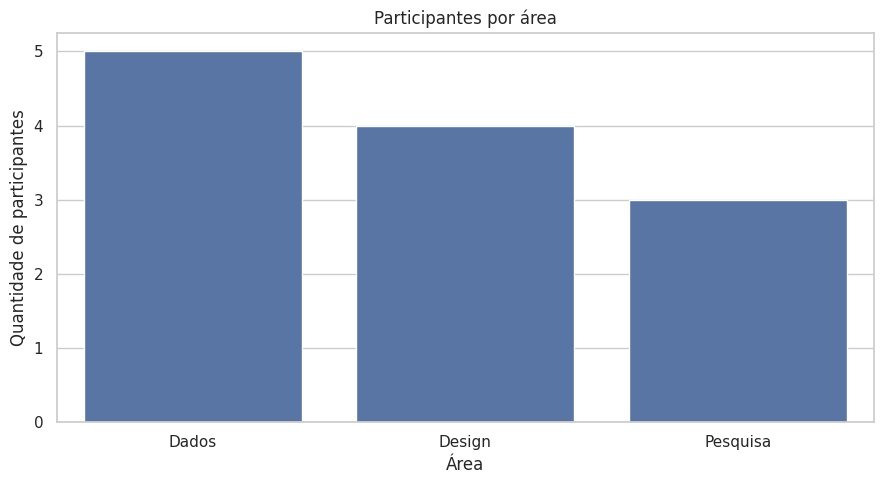

In [7]:
ordem = df["area"].value_counts().index
sns.countplot(data=df, x="area", order=ordem)
plt.title("Participantes por área")
plt.xlabel("Área")
plt.ylabel("Quantidade de participantes")
plt.tight_layout()
plt.show()

### 8.2 Histograma — observar distribuição

Pergunta: como estão distribuídas as notas dos projetos?

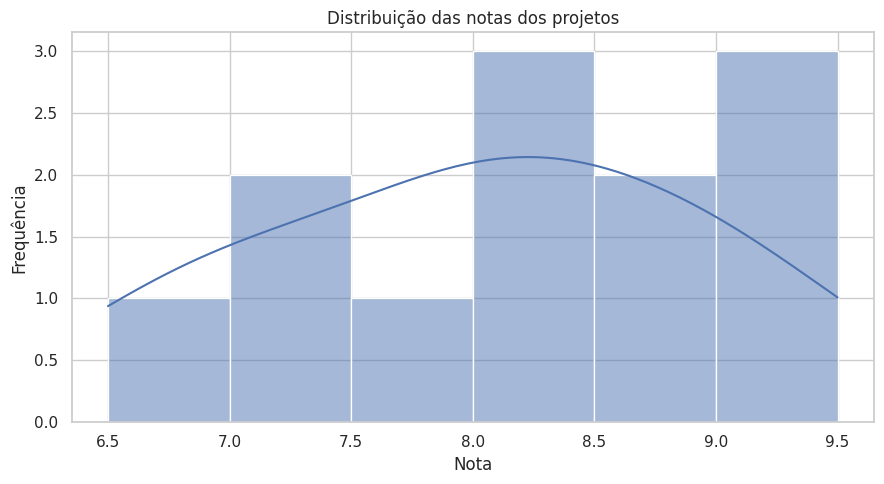

In [8]:
sns.histplot(data=df, x="nota_projeto", bins=6, kde=True)
plt.title("Distribuição das notas dos projetos")
plt.xlabel("Nota")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

### 8.3 Boxplot — comparar distribuição

O boxplot resume mediana, quartis e possíveis pontos extremos. Um ponto extremo precisa ser investigado; não é necessariamente um erro.

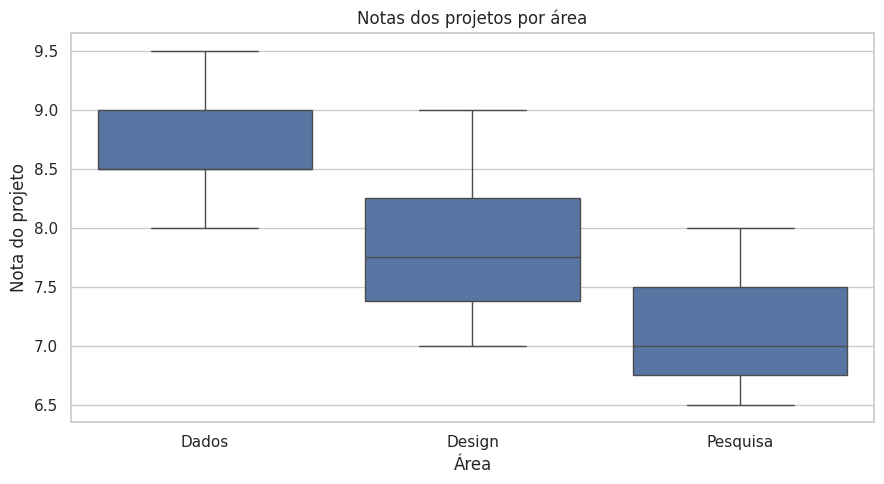

In [9]:
sns.boxplot(data=df, x="area", y="nota_projeto")
plt.title("Notas dos projetos por área")
plt.xlabel("Área")
plt.ylabel("Nota do projeto")
plt.tight_layout()
plt.show()

### 8.4 Dispersão — observar relação entre variáveis

Pergunta: neste conjunto, horas de estudo parecem acompanhar notas maiores?

Uma associação visual não prova que uma variável causa a outra.

In [ ]:
sns.scatterplot(data=df_tratado, x="horas_estudo", y="nota_projeto",
                hue="area", s=100)
plt.title("Horas de estudo e nota do projeto")
plt.xlabel("Horas de estudo")
plt.ylabel("Nota do projeto")
plt.tight_layout()
plt.show()

### 8.5 Correlação

A correlação mede a intensidade e a direção de uma relação linear. Valores próximos de `1` indicam associação positiva; próximos de `-1`, negativa; próximos de `0`, pouca associação linear.

**Correlação não implica causalidade.** Ela também pode ser influenciada por valores extremos e por outras variáveis.

,idade,horas_estudo,nota_projeto,presencas
idade,1.00,0.28,0.16,0.36
horas_estudo,0.28,1.00,0.91,0.84
nota_projeto,0.16,0.91,1.00,0.89
presencas,0.36,0.84,0.89,1.00


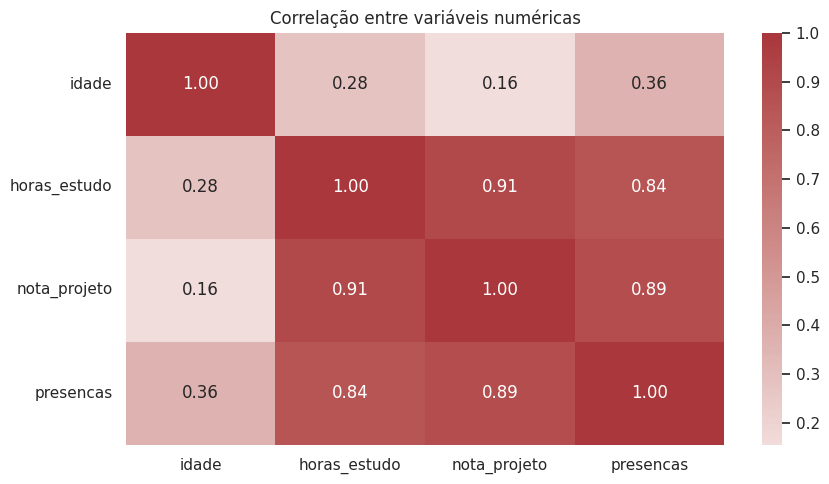

In [6]:
numericas = df_tratado.select_dtypes(include="number")
correlacao = numericas.corr()
display(correlacao.round(2))

sns.heatmap(correlacao, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)

# 1. Criação do DataFrame original
dados = {
    "participante": ["Ana", "Bruno", "Caio", "Duda", "Elisa", "Fábio",
                     "Gabi", "Hugo", "Iara", "João", "Lia", "Maya"],
    "idade": [19, 22, 21, 24, 20, 23, 22, 25, 19, 21, 26, 20],
    "cidade": ["Recife", "Olinda", "Recife", "Paulista", "Olinda", "Recife",
               "Jaboatão", "Recife", "Olinda", "Paulista", "Recife", "Olinda"],
    "area": ["Dados", "Design", "Dados", "Pesquisa", "Design", "Dados",
             "Pesquisa", "Design", "Dados", "Pesquisa", "Design", "Dados"],
    "horas_estudo": [5.0, 3.5, 6.0, 4.0, np.nan, 7.0, 2.5, 5.5, 4.5, 3.0, 6.5, 5.0],
    "nota_projeto": [8.5, 7.0, 9.0, 8.0, 7.5, 9.5, 6.5, 8.0, 8.5, 7.0, 9.0, 8.0],
    "presencas": [9, 8, 10, 9, 7, 10, 6, 9, 8, 7, 10, 9],
    "data_inscricao": ["2026-03-02", "2026-03-03", "2026-03-03", "2026-03-04",
                       "2026-03-05", "2026-03-05", "2026-03-06", "2026-03-06",
                       "2026-03-07", "2026-03-07", "2026-03-08", "2026-03-08"]
}
df = pd.DataFrame(dados)

# 2. Criação do DataFrame tratado (df_tratado)
df_tratado = df.copy()
mediana_horas = df_tratado["horas_estudo"].median()
df_tratado["horas_estudo"] = df_tratado["horas_estudo"].fillna(mediana_horas)
df_tratado["data_inscricao"] = pd.to_datetime(df_tratado["data_inscricao"])

print("Ambiente preparado com sucesso! 'df' e 'df_tratado' prontos para uso.")

Ambiente preparado com sucesso! 'df' e 'df_tratado' prontos para uso.


## 9. Agrupamento com Pandas

`groupby` permite resumir dados por categoria. Aqui calculamos quantidade de participantes, nota média e horas médias por área.

In [ ]:
resumo_area = (
    df_tratado.groupby("area")
    .agg(
        participantes=("participante", "count"),
        nota_media=("nota_projeto", "mean"),
        horas_medias=("horas_estudo", "mean")
    )
    .round(2)
    .sort_values("nota_media", ascending=False)
)
display(resumo_area)

## 10. NumPy: operações numéricas

O NumPy oferece arrays e operações vetorizadas, permitindo realizar cálculos sobre vários valores de uma vez.

In [ ]:
notas = np.array(df["nota_projeto"])
print("Array:", notas)
print("Média:", np.mean(notas))
print("Mediana:", np.median(notas))
print("Desvio padrão:", np.std(notas))
print("Notas acima de 8:", notas[notas > 8])

# Exemplo: converter escala de 0–10 para 0–100
print("Escala percentual:", notas * 10)

## 11. Como registrar os achados

Uma boa análise não termina no gráfico. Registre:
1. **Pergunta:** o que você queria descobrir?
2. **Evidência:** qual tabela, estatística ou gráfico observou?
3. **Interpretação:** o que os dados sugerem?
4. **Limitação:** o que não é possível concluir?
5. **Próximo passo:** que informação ajudaria?

Exemplo: “Neste pequeno conjunto fictício, o gráfico permite explorar uma possível associação entre horas de estudo e nota. Porém, a quantidade de registros é pequena e não permite concluir que estudar mais causa notas maiores.”

## 12. Exercícios

Tente resolver antes de consultar as sugestões de código.

1. **Inspeção:** quantas linhas e colunas existem? Quais colunas são numéricas? Qual coluna contém ausência?
2. **Frequências:** qual cidade aparece mais vezes? Quantos participantes são da área de Dados?
3. **Estatística:** calcule média e mediana das notas. São iguais?
4. **Visualização:** faça um gráfico de barras por cidade e um histograma de horas de estudo.
5. **Investigação:** compare a nota média por área. Escreva uma observação e uma limitação.

In [10]:
# Exercício 1
print("Dimensões:", df.shape)
display(df.dtypes)
display(df.isna().sum())

Dimensões: (12, 8)


,0
participante,object
idade,int64
cidade,object
area,object
horas_estudo,float64
nota_projeto,float64
presencas,int64
data_inscricao,object


,0
participante,0
idade,0
cidade,0
area,0
horas_estudo,1
nota_projeto,0
presencas,0
data_inscricao,0


In [ ]:
# Exercício 2
display(df["cidade"].value_counts())
display(df["area"].value_counts())

In [ ]:
# Exercício 3
print("Média:", df["nota_projeto"].mean())
print("Mediana:", df["nota_projeto"].median())

In [ ]:
# Exercício 4 — gráfico por cidade
sns.countplot(data=df, x="cidade")
plt.xticks(rotation=30)
plt.title("Participantes por cidade")
plt.tight_layout()
plt.show()

# Histograma de horas de estudo
sns.histplot(data=df, x="horas_estudo", bins=5)
plt.title("Distribuição das horas de estudo")
plt.tight_layout()
plt.show()

In [ ]:
# Exercício 5
display(df.groupby("area")["nota_projeto"].mean().sort_values(ascending=False))

## 13. Referência rápida

| Objetivo | Comando |
|---|---|
| Primeiras linhas | `df.head()` |
| Dimensões | `df.shape` |
| Tipos e ausências | `df.info()` |
| Estatísticas | `df.describe()` |
| Frequência de categorias | `df["coluna"].value_counts()` |
| Ausências | `df.isna().sum()` |
| Duplicatas | `df.duplicated().sum()` |
| Filtrar | `df.loc[condicao]` |
| Agrupar | `df.groupby("coluna").agg(...)` |
| Correlação | `df.corr(numeric_only=True)` |
| Histograma | `sns.histplot(...)` |
| Barras | `sns.countplot(...)` |
| Dispersão | `sns.scatterplot(...)` |
| Boxplot | `sns.boxplot(...)` |

## Encerramento

EDA é uma prática de curiosidade disciplinada: observar, questionar, verificar e comunicar. O objetivo não é produzir o maior número de gráficos, mas construir uma compreensão confiável dos dados e descobrir quais perguntas devem vir em seguida.

**Próximo passo:** escolha um conjunto de dados de seu interesse e repita o fluxo desta aula, registrando suas decisões e justificativas.

# Exercício final para casa — Explorando a base Iris

**Objetivo:** aplicar o fluxo de Análise Exploratória de Dados (EDA) a uma base clássica de aprendizagem de máquina: o conjunto **Iris**, disponível no scikit-learn.

A base contém medidas de flores de três espécies: *setosa*, *versicolor* e *virginica*. Cada registro representa uma flor; as variáveis incluem comprimento e largura das sépalas e das pétalas.

## Carregando a base

Execute a célula abaixo. Esta é a única célula de código fornecida para iniciar a atividade. Faça as análises e construa as visualizações necessárias por conta própria, usando os recursos estudados em aula.

In [24]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df_iris = iris.frame
df_iris["species"] = df_iris["target"].map(dict(enumerate(iris.target_names)))
df_iris = df_iris.drop(columns="target")

display(df_iris.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## As três perguntas da investigação

Responda usando tabelas, estatísticas e visualizações adequadas. Não basta apresentar um gráfico: escreva uma interpretação em suas próprias palavras e explique o que os dados permitem — ou não permitem — concluir.


### 1. Como as três espécies estão representadas na base?

Investigue a quantidade de flores de cada espécie.

Na resposta:
- informe quantas observações existem para cada espécie;
- compare as quantidades;
- apresente uma visualização que ajude a comparar as espécies.

,Número de flores
species,
setosa,50
versicolor,50
virginica,50


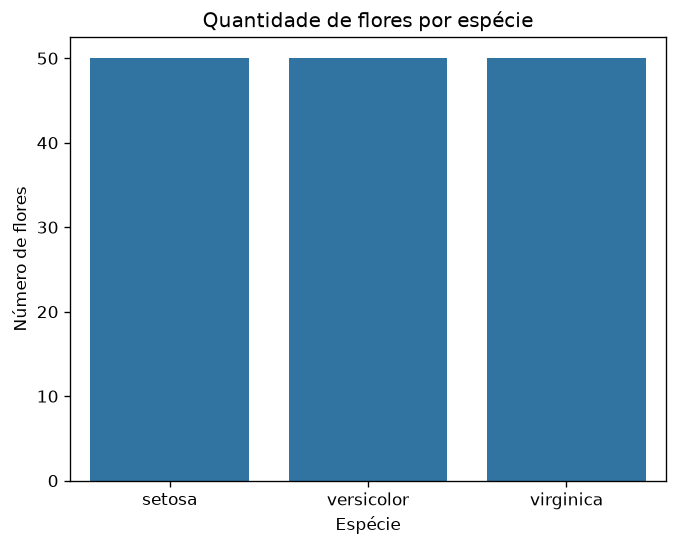

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Cada linha representa uma flor. Contamos quantas linhas têm cada nome.
contagem = df_iris["species"].value_counts().sort_index()
display(contagem.rename("Número de flores"))

sns.countplot(data=df_iris, x="species", order=contagem.index)
plt.title("Quantidade de flores por espécie")
plt.xlabel("Espécie")
plt.ylabel("Número de flores")
plt.show()

**Resposta.** Das 150 flores, 50 são setosa, 50 são versicolor e 50 são virginica. As barras têm a mesma altura porque cada espécie representa um terço da amostra. Essa contagem descreve as flores selecionadas para a base.

### 2. Quais características das pétalas melhor diferenciam as espécies?

Compare o comprimento e a largura das pétalas entre *setosa*, *versicolor* e *virginica*.

Na resposta:
- apresente medidas-resumo que permitam comparar as espécies;
- use pelo menos uma visualização adequada;
- indique qual característica parece separar melhor as espécies e justifique sua interpretação com evidências da base.

petal length (cm)             petal width (cm)            
                         min median  max              min median  max
species                                                              
setosa                   1.0   1.50  1.9              0.1    0.2  0.6
versicolor               3.0   4.35  5.1              1.0    1.3  1.8
virginica                4.5   5.55  6.9              1.4    2.0  2.5

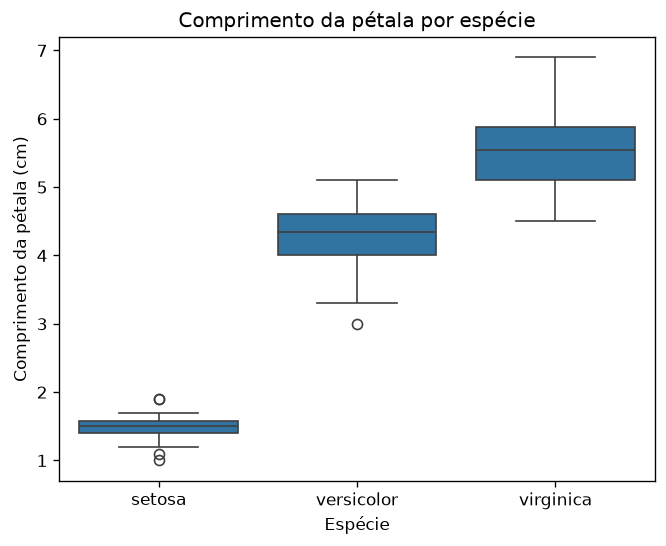

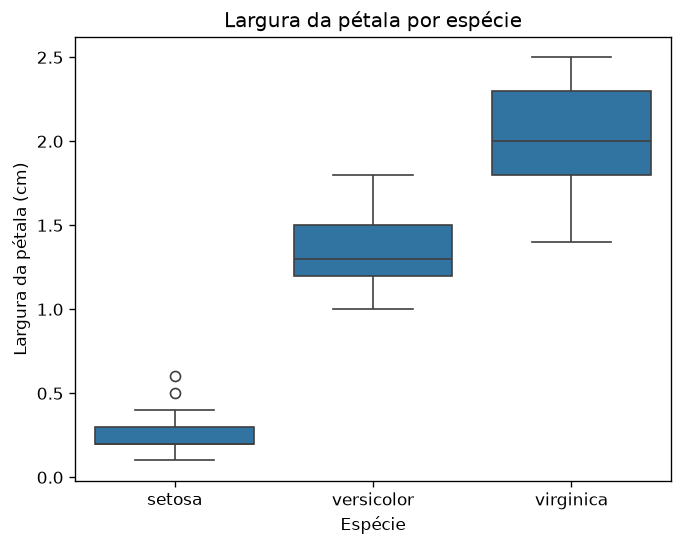

In [26]:
comprimento = "petal length (cm)"
largura = "petal width (cm)"

# Cada linha da tabela resume uma espécie. As medidas estão em centímetros.
resumo = df_iris.groupby("species")[[comprimento, largura]].agg(["min", "median", "max"])
display(resumo)

# No boxplot, o traço dentro da caixa marca a mediana.
for coluna, medida in [(comprimento, "Comprimento"), (largura, "Largura")]:
    sns.boxplot(data=df_iris, x="species", y=coluna)
    plt.title(f"{medida} da pétala por espécie")
    plt.xlabel("Espécie")
    plt.ylabel(f"{medida} da pétala (cm)")
    plt.show()

**Resposta.** As duas medidas distinguem bem a setosa. Sua maior pétala mede 1,9 cm de comprimento e 0,6 cm de largura. Entre as versicolor, os menores valores já são 3,0 cm e 1,0 cm. A virginica tem as maiores medianas nas duas medidas.

Para distinguir versicolor de virginica, usei como critério a faixa em que os valores das duas espécies coincidem, em centímetros. No comprimento, essa faixa vai de 4,5 a 5,1 cm. Na largura, vai de 1,4 a 1,8 cm. **Por esse critério, a largura parece separar melhor** essas duas espécies, pois a faixa compartilhada é menor (0,4 cm contra 0,6 cm). Mesmo assim, uma flor com pétala de 1,5 cm de largura pode pertencer a qualquer uma das duas. Essa comparação descreve os intervalos observados e não mede a taxa de acerto de uma classificação.

### 3. Existe uma relação entre o comprimento da sépala e o comprimento da pétala?

Investigue a relação entre essas duas medidas considerando o conjunto completo e observando também as espécies.

Na resposta:
- apresente um gráfico adequado para observar a relação;
- descreva o padrão encontrado;
- explique se a relação parece igual nas três espécies;
- lembre-se: uma associação observada não prova que uma característica cause a outra.

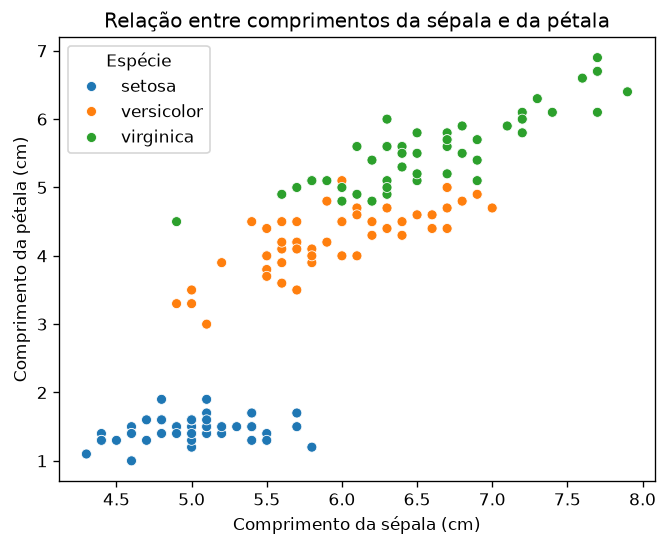

,Correlação
Todas as flores,0.87
setosa,0.27
versicolor,0.75
virginica,0.86


In [27]:
sepala = "sepal length (cm)"
petala = "petal length (cm)"

sns.scatterplot(data=df_iris, x=sepala, y=petala, hue="species")
plt.title("Relação entre comprimentos da sépala e da pétala")
plt.xlabel("Comprimento da sépala (cm)")
plt.ylabel("Comprimento da pétala (cm)")
plt.legend(title="Espécie")
plt.show()

# Comparamos a correlação do conjunto inteiro com a de cada espécie.
correlacoes = {"Todas as flores": df_iris[sepala].corr(df_iris[petala])}
for especie, grupo in df_iris.groupby("species"):
    correlacoes[especie] = grupo[sepala].corr(grupo[petala])
display(pd.Series(correlacoes, name="Correlação").round(2))

**Resposta.** Cada ponto representa uma flor. No conjunto, os pontos tendem a subir da esquerda para a direita: sépalas mais compridas costumam acompanhar pétalas mais compridas (correlação de 0,87). Ao comparar apenas pontos da mesma cor, a tendência é forte em versicolor (0,75) e virginica (0,86) e fraca em setosa (0,27). O padrão geral reúne tanto a variação entre flores da mesma espécie quanto as diferenças de tamanho entre espécies. Essa associação não prova que o crescimento de uma parte cause o da outra.

## Entrega

Organize as respostas no próprio notebook, abaixo de cada pergunta, incluindo:
- código usado na análise;
- tabelas ou estatísticas relevantes;
- gráficos com título e nomes dos eixos;
- uma interpretação escrita para cada pergunta.

**Conclusão final:** escreva um pequeno parágrafo resumindo o que descobriu sobre a base Iris e cite uma limitação da sua análise.

**Critério principal:** valorize a qualidade da investigação e da interpretação, não a quantidade de gráficos. Explique como cada resultado ajuda a responder à pergunta.

### Conclusão final

As três espécies têm a mesma quantidade de flores na base. As pétalas da setosa se destacam pelo tamanho menor, enquanto algumas medidas de versicolor e virginica se sobrepõem. O comprimento da sépala acompanha o da pétala no conjunto, mas a intensidade dessa relação varia conforme a espécie. Uma limitação é que a análise descreve as 150 flores observadas: as proporções encontradas aqui não informam a frequência das espécies na natureza.